In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

In [3]:
df = pd.read_csv("/content/eda_dataset.csv")

In [6]:
print(df.columns)

Index(['Doc_ID', 'Nama_Tempat', 'Lokasi', 'Provinsi', 'Kabupaten',
       'Kategori_Harga', 'Waktu_CheckIn', 'Has_Toilet', 'Has_Mushola',
       'Has_Listrik', 'Has_Parkir', 'Has_Air_Bersih', 'Has_WiFi', 'Has_Warung',
       'Has_Gazebo', 'Has_Kolam', 'Has_Pemandu', 'Rating', 'Kategori_Rating',
       'Sentimen_Ulasan', 'Harga_Tiket_Masuk', 'Harga_Min', 'Harga_Max',
       'Harga_Rata2', 'Jumlah_Item_Harga', 'Jumlah_Fasilitas',
       'Rating_Rata2_Tempat', 'Jumlah_Ulasan_Tempat', 'Rating_Min_Tempat',
       'Rating_Max_Tempat', 'Panjang_Teks', 'Teks_Mentah'],
      dtype='object')


In [4]:
df.dropna(inplace=True)

In [7]:
df.drop(df[df['Sentimen_Ulasan'] == 2].index, inplace=True)

In [8]:
categorical_cols = df.select_dtypes(include=['object']).columns
print(categorical_cols)

Index(['Nama_Tempat', 'Lokasi', 'Provinsi', 'Kabupaten', 'Kategori_Harga',
       'Waktu_CheckIn', 'Has_Toilet', 'Has_Mushola', 'Has_Listrik',
       'Has_Parkir', 'Has_Air_Bersih', 'Has_WiFi', 'Has_Warung', 'Has_Gazebo',
       'Has_Kolam', 'Has_Pemandu', 'Kategori_Rating', 'Sentimen_Ulasan',
       'Teks_Mentah'],
      dtype='object')


In [9]:
le = LabelEncoder()
for col in categorical_cols:
  df[col] = le.fit_transform(df[col])

In [11]:
X = df.drop(['Sentimen_Ulasan'], axis=1)
y = df['Sentimen_Ulasan']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Sentimen_Ulasan
2    176
1     64
0     42
Name: count, dtype: int64
Sentimen_Ulasan
2    0.624113
1    0.226950
0    0.148936
Name: proportion, dtype: float64


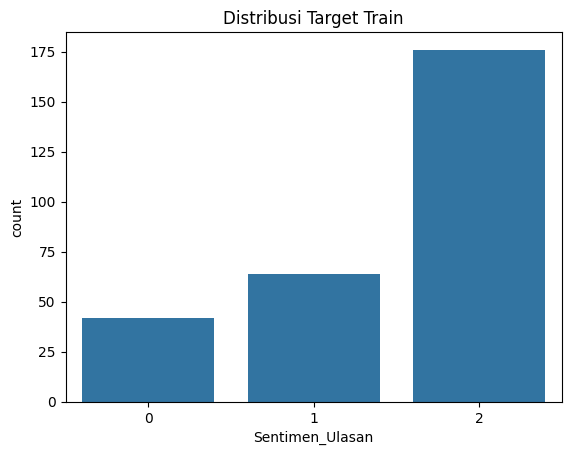

In [12]:
print(y_train.value_counts())

print(y_train.value_counts(normalize=True))
sns.countplot(x=y_train)
plt.title("Distribusi Target Train")
plt.show()

Accuracy: 0.5915492957746479
Precision 0.6285386739038884
Recall 0.5915492957746479
F1 Score 0.604088480727626
Classification Report:
               precision    recall  f1-score   support

           0       0.21      0.38      0.27         8
           1       0.64      0.47      0.55        19
           2       0.70      0.68      0.69        44

    accuracy                           0.59        71
   macro avg       0.52      0.51      0.50        71
weighted avg       0.63      0.59      0.60        71



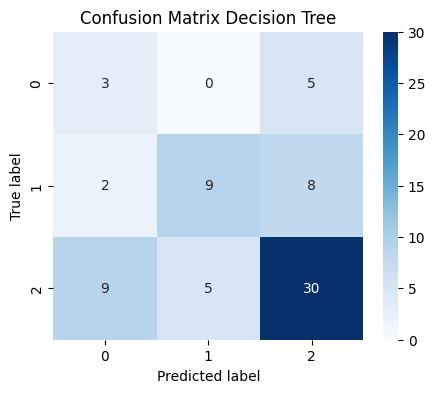

In [13]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_dt))
print('Precision', precision_score(y_test, y_pred_dt, average='weighted'))
print('Recall', recall_score(y_test, y_pred_dt, average='weighted'))
print('F1 Score', f1_score(y_test, y_pred_dt, average='weighted'))
print('Classification Report:\n', classification_report(y_test, y_pred_dt))

#Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix Decision Tree')
plt.show()

Accuracy: 0.6197183098591549
Precision 0.5931841046277666
Recall 0.6197183098591549
F1 Score 0.6040803963566345
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       0.56      0.47      0.51        19
           2       0.71      0.80      0.75        44

    accuracy                           0.62        71
   macro avg       0.43      0.42      0.42        71
weighted avg       0.59      0.62      0.60        71



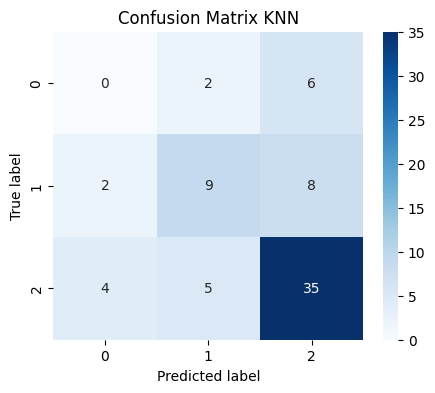

In [14]:
knn_model = KNeighborsClassifier()

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_knn))
print('Precision', precision_score(y_test, y_pred_knn, average='weighted'))
print('Recall', recall_score(y_test, y_pred_knn, average='weighted'))
print('F1 Score', f1_score(y_test, y_pred_knn, average='weighted'))
print('Classification Report:\n', classification_report(y_test, y_pred_knn))

#Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix KNN')
plt.show()

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no pre

Accuracy: 0.704225352112676
Precision: 0.657137268052761
Recall: 0.704225352112676
F1 Score: 0.6368498286360601
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       0.88      0.37      0.52        19
           2       0.68      0.98      0.80        44

    accuracy                           0.70        71
   macro avg       0.52      0.45      0.44        71
weighted avg       0.66      0.70      0.64        71



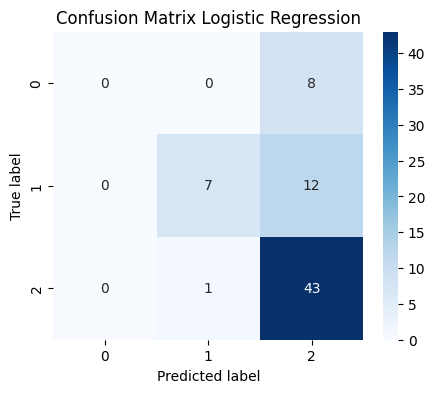

In [16]:
lr_model = LogisticRegression(max_iter=1000, random_state=0)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr, average='weighted'))
print('Recall:', recall_score(y_test, y_pred_lr, average='weighted'))
print('F1 Score:', f1_score(y_test, y_pred_lr, average='weighted'))
print('Classification Report:\n', classification_report(y_test, y_pred_lr))

#Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix Logistic Regression')
plt.show()

Accuracy: 0.6901408450704225
Precision: 0.6743834655442232
Recall: 0.6901408450704225
F1 Score: 0.6507870753935378
Classification Report:
               precision    recall  f1-score   support

           0       0.25      0.12      0.17         8
           1       0.78      0.37      0.50        19
           2       0.71      0.93      0.80        44

    accuracy                           0.69        71
   macro avg       0.58      0.48      0.49        71
weighted avg       0.67      0.69      0.65        71



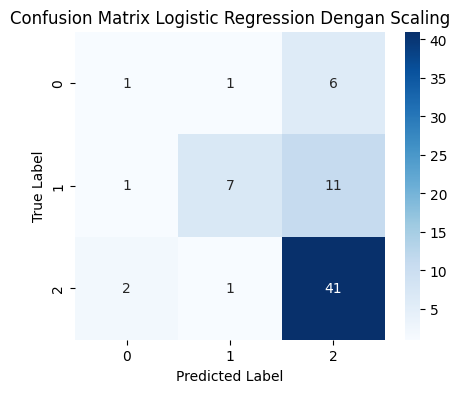

In [17]:
lr_model = LogisticRegression(max_iter=1000, random_state=0)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr, average='weighted'))
print('Recall:', recall_score(y_test, y_pred_lr, average='weighted'))
print('F1 Score:', f1_score(y_test, y_pred_lr, average='weighted'))
print('Classification Report:\n', classification_report(y_test, y_pred_lr))

#Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix Logistic Regression Dengan Scaling")
plt.show()